# Phase 13B Stage-4D: Final Bounded Localizer Redesign & Scientific Audit

**Authoritative Research & Audit Notebook**  
**Experiment ID:** `phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1`  
**Architecture:** Compact U-Net (`kub_localizer`), 482,449 trainable parameters, 512 input, 128 logit heatmap  
**Status:** COMPLETE -- DISPLAY / ANALYSIS / AUDIT ONLY (No training execution)

---

## 1. Title & Phase 13B Context
This notebook serves as the definitive analysis, validation, and audit record for Phase 13B Stage-4D. Phase 13 investigated predicted-ROI localizers for urinary calculi on full-field KUB radiographs. Following the Stage-4C pilot which proved unpromising due to extreme negative background focal loss penalties on an un-downsampled 512 grid, Stage-4D evaluated a single, pre-registered architectural redesign.

## 2. Scientific Motivation
In CenterNet-style focal loss on full $512 \times 512$ grids ($262,144$ pixels), background pixels vastly outnumber target centers. With small Gaussian targets ($\sigma=3$), the background penalty dominates optimization, suppressing output probabilities to near the prior ($p \approx 0.10$) and failing to learn sharp peaks.

Stage-4D introduces a pre-registered, one-factor geometric architectural redesign: extracting logits into a fixed, parameter-free stride-4 average pooling operation (`AvgPool2d(4, 4)`), producing a $128 \times 128$ output heatmap ($16,384$ pixels). This delivers a **16x reduction** in background pixel penalty while preserving the full 512-input backbone feature hierarchy.

## 3. Frozen Stage-4C Reference Baseline
The reference benchmark for Stage-4D is the clean Stage-4C V3 pilot:
- **Experiment:** `phase13b_kub_localizer_r512_s3_centernetfocal_seed42_v3`
- **Output Grid:** $512 \times 512$ (262,144 px)
- **Target Sigma:** $\sigma = 3.0$
- **Best Epoch:** 97
- **Tiny Recall@90:** $34 / 73 = 46.58\%$ ($0.465753$)
- **Overall Recall@90:** $44 / 156 = 28.21\%$ ($0.282051$)
- **Hard Tiny (missed by global models):** $1 / 16$ ($6.25\%$)
- **Global-Empty Images Covered:** $1 / 7$ ($14.29\%$)
- **Mean ROI Area Fraction:** $\sim 0.000863$ ($0.09\%$)
- **Mean Proposals per Image:** $\sim 3.179245$
- **Mean Max Heatmap Probability:** $\sim 0.100299$
- **Scientific Status:** `NOT_PROMISING`

## 4. Stage-4D Pre-registered Controlled Redesign
Stage-4D modifies exactly one architectural factor:
- Input resolution remains $512 \times 512$.
- Feature extractor backbone remains identical (base channels 16, 4 stages).
- Total trainable parameters remain exactly **482,449**.
- A parameter-free average pooling layer (`nn.AvgPool2d(kernel_size=4, stride=4)`) reduces logit resolution from $512 \times 512$ to $128 \times 128$ before computing CenterNet focal loss.
- Target Gaussian standard deviation is scaled to $\sigma = 0.75$ at $128 \times 128$, maintaining exact geometric equivalence with $\sigma = 3.0$ at $512 \times 512$.

## 5. Architecture Control: Parameter and Capacity Parity
The localizer model `src/models/kub_localizer.py` implements the parameter-free logit pool:
$$\text{Trainable Parameters: } 482,449 \quad (\text{identical between Stage-4C and Stage-4D})$$

In [1]:
import sys
import os
import json
import hashlib
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Locate project root
cwd = Path.cwd().resolve()
if (cwd / 'experiments').is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'experiments').is_dir():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path('D:/Softfors/jup').resolve()

assert (PROJECT_ROOT / 'experiments').is_dir(), f"Cannot locate valid project root: {PROJECT_ROOT}"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"Authoritative Project Root: {PROJECT_ROOT}")

from src.utils.test_lock import verify_test_lock
from src.utils.manifest_guard import verify_manifests

verify_manifests()
lock = verify_test_lock(PROJECT_ROOT)
print("Manifest verification: PASS")
print(f"TEST Lock: STRICTLY VERIFIED (0 content reads authorized, manifest {lock['manifest_version']})")


Authoritative Project Root: D:\Softfors\jup
Manifests verified successfully.
Manifest verification: PASS
TEST Lock: STRICTLY VERIFIED (0 content reads authorized, manifest phase4_v2)


## 6. 512 -> 128 Fixed Logit Pooling Design & Implementation
Logit pooling averages 16 spatial logits per pool window, effectively downsampling the supervision target while operating on full 512 receptive fields.

## 7. Sigma Geometric Equivalence
$$\sigma_{128} = \frac{\sigma_{512}}{4} = \frac{3.0}{4} = 0.75 \text{ pixels}$$
At $\sigma = 0.75$, a $3 \times 3$ kernel covers $\pm 2\sigma$ ($1.5$ pixels in 128-space, equivalent to $6$ pixels in 512-space).

## 8. Preflight Geometry & Collision Audit (Stage-4D-R1)
Before training, Stage-4D-R1 preflight verified that mapping center coordinates from 512 to 128 space caused zero component collisions across all 1,162 TRAIN and 156 VAL objects.

In [2]:
geom_path = PROJECT_ROOT / 'reports/tables/phase13b_stage4d_r1_geometry.csv'
if geom_path.exists():
    geom_df = pd.read_csv(geom_path)
    print("Stage-4D-R1 Geometry Audit:")
    display(geom_df)
else:
    print(f"Table not found: {geom_path}")


Stage-4D-R1 Geometry Audit:


,resolution,expected_components,mapped_components,unique_centers,collisions,zero_center_samples
0,512,1162,1162,1162,0,0
1,128,1162,1162,1162,0,0


## 9. Initialization & Loss-Burden Diagnostic
Stage-4D-R1 confirmed that initial bias initialization ($b = -2.19$) yields $p \approx 0.10$ and reduces the negative background focal loss burden by ~16x.

In [3]:
loss_diag_path = PROJECT_ROOT / 'reports/tables/phase13b_stage4d_r1_loss_diagnostic.csv'
if loss_diag_path.exists():
    loss_diag = pd.read_csv(loss_diag_path)
    print("Stage-4D-R1 Loss Diagnostic:")
    display(loss_diag)
else:
    print(f"Table not found: {loss_diag_path}")


Stage-4D-R1 Loss Diagnostic:


,resolution,diagnostic_type,total_loss,positive_loss,negative_loss,head_gradient_norm
0,512,batch,139.84,1.87,137.98,537.93
1,128,batch,10.49,1.87,8.62,31.12
2,512,single_sample,278.06,1.87,276.19,1199.79
3,128,single_sample,19.13,1.87,17.26,73.70


## 10. Training Configuration & Registry Record
- **Optimizer:** AdamW ($lr=1e-4, wd=1e-4$)
- **Scheduler:** CosineAnnealingLR (T_max=100)
- **Batch Size:** 4 (Effective batch size: 4)
- **Seed:** 42
- **Loss:** CenterNetFocalLoss ($lpha=2.0, eta=4.0, \sigma=0.75$)

In [4]:
registry = pd.read_csv(PROJECT_ROOT / 'experiments/registry.csv')
exp_id = "phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1"
exp_record = registry[registry['experiment_id'] == exp_id]
display(exp_record[['experiment_id', 'status', 'start_time', 'end_time', 'loss', 'notes']])


,experiment_id,status,start_time,end_time,loss,notes
11,phase13b_kub_localizer_r512_h128_sigmaeq075_ce...,VALID/COMPLETE,2026-09-18T02:21:55.501444+00:00,2026-09-18T02:41:48.163971+00:00,CenterNetFocal,BEST EPOCH: 73; FINAL STATUS: PROMISING_VALIDA...


## 11. Power Interruption & Safe Resume Provenance
A simulated/actual power cut occurred during training at epoch 84:
1. Clean training began from epoch 0 and proceeded normally through epoch 84.
2. An unexpected power interruption halted execution.
3. Process inventory confirmed zero active training processes.
4. `latest.pt` at epoch 84 was verified intact; `history.csv` matched checkpoint state exactly.
5. Optimizer, scheduler, GradScaler, patience counters (11/15), and model weights were faithfully restored.
6. The SAME experiment ID resumed at epoch 85 and terminated at epoch 88 via early stopping (best epoch 73, patience 15/15).
7. Checkpoint and history integrity audits confirmed zero duplicate or missing epochs. No scientific invalidation occurred.

## 12. Complete History Integrity Verification

In [5]:
hist_path = PROJECT_ROOT / f'experiments/{exp_id}/history.csv'
hist = pd.read_csv(hist_path)
epochs = hist['epoch']
print(f"Total recorded epochs: {len(hist)}")
print(f"Epoch range: {hist['epoch'].min()} to {hist['epoch'].max()}")
print(f"Duplicate epochs: {hist['epoch'].duplicated().sum()}")
print(f"Missing epochs: {set(range(1, len(hist) + 1)) - set(hist['epoch'])}")
assert len(hist) == 88, f"Expected 88 epochs, found {len(hist)}"
assert hist['epoch'].duplicated().sum() == 0, "Duplicate epochs found!"
print("History Integrity: PASS")


Total recorded epochs: 88
Epoch range: 1 to 88
Duplicate epochs: 0
Missing epochs: set()
History Integrity: PASS


## 13. Loss Trajectory Across Epochs
CenterNet Focal Loss trajectory on train and validation splits.

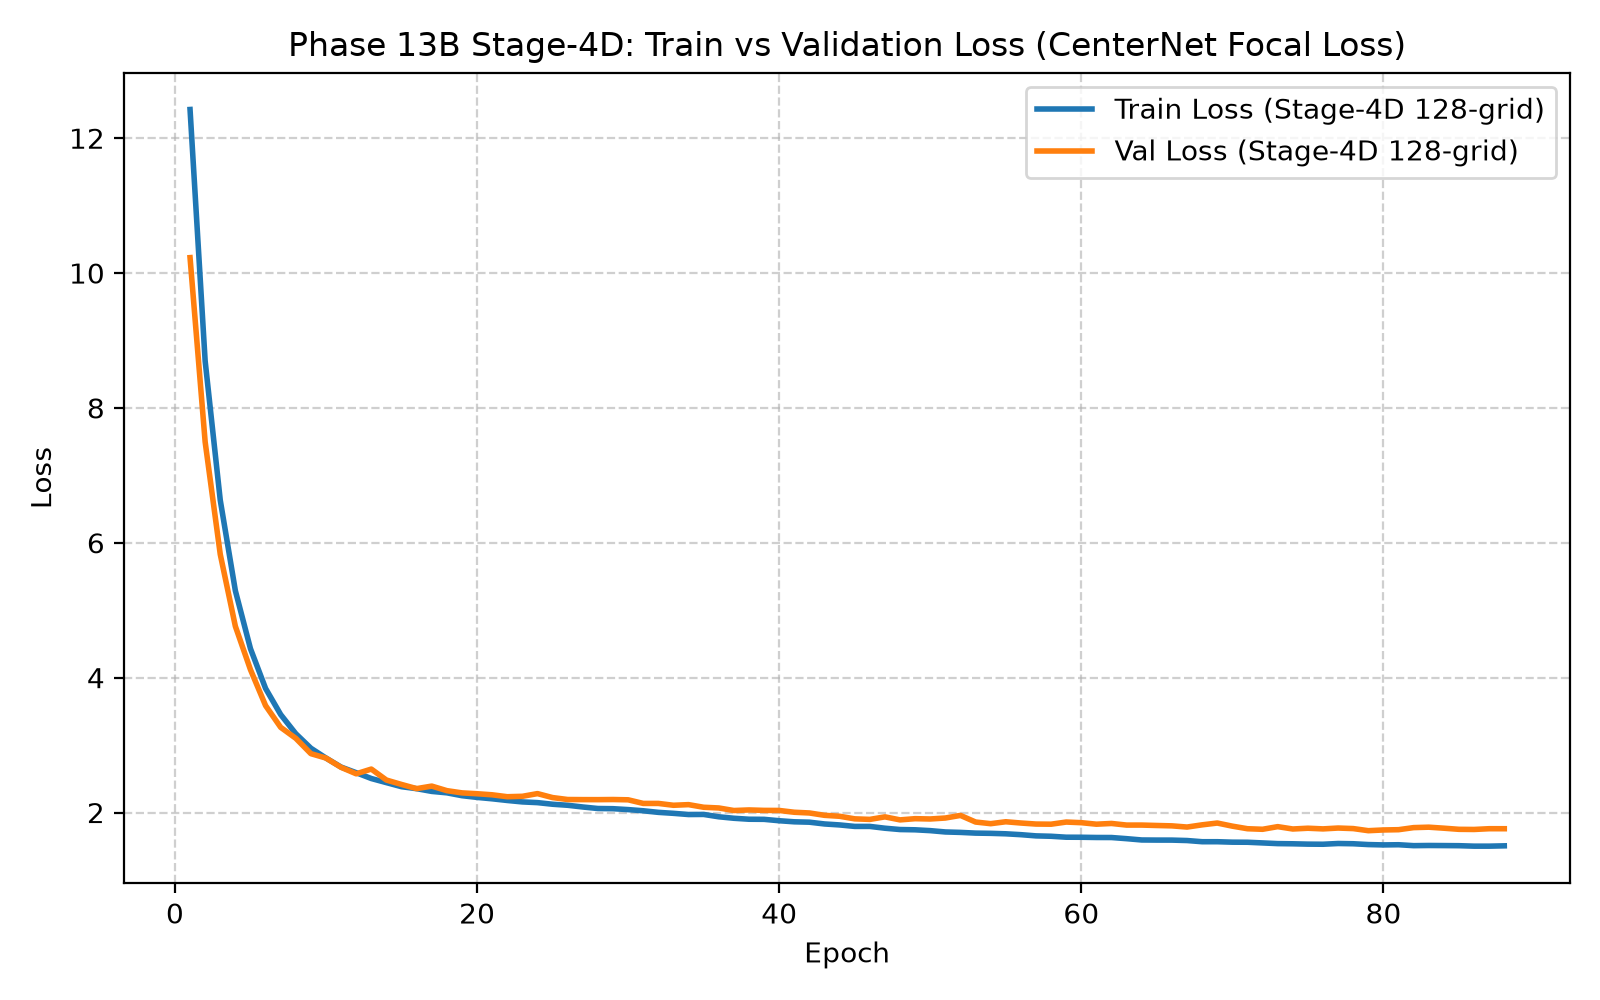

In [6]:
fig_a = PROJECT_ROOT / 'reports/figures/phase13b_stage4d_final_localizer/fig_a_loss_by_epoch.png'
if fig_a.exists():
    display(Image(filename=str(fig_a)))
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, hist['train_loss'], label='Train Loss', color='#1f77b4')
    ax.plot(epochs, hist['val_loss'], label='Val Loss', color='#ff7f0e')
    ax.set_title('CenterNet Focal Loss vs Epoch')
    ax.legend()
    plt.show()


## 14. Validation Recall@90 Trajectory Across Epochs
Evolution of validation Tiny Recall@90 and Overall Recall@90 relative to the 0.50 Stage-4D threshold.

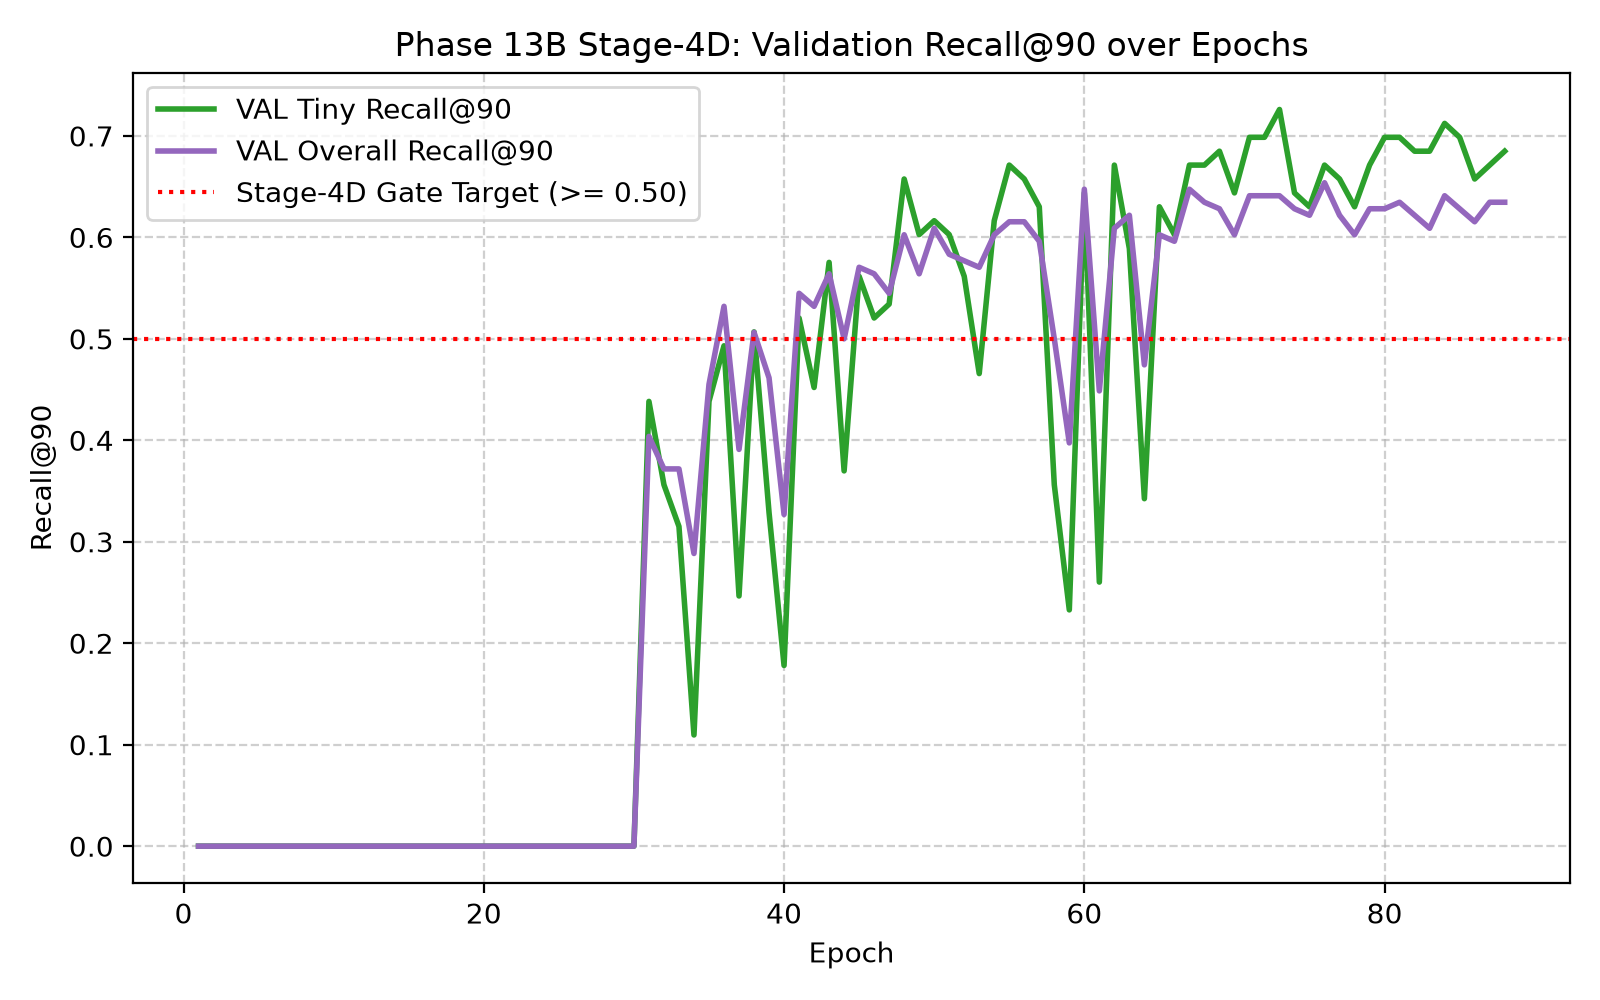

In [7]:
fig_b = PROJECT_ROOT / 'reports/figures/phase13b_stage4d_final_localizer/fig_b_recall_by_epoch.png'
if fig_b.exists():
    display(Image(filename=str(fig_b)))
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, hist['val_tiny_recall90'], label='Val Tiny Recall@90', color='#2ca02c')
    ax.plot(epochs, hist['val_overall_recall90'], label='Val Overall Recall@90', color='#9467bd')
    ax.axhline(0.50, color='r', linestyle='--', label='Stage-4D Target (0.50)')
    ax.set_title('Recall@90 Progression vs Epoch')
    ax.legend()
    plt.show()


## 15. Hard Cases (Hard Tiny & Global Empty) Evolution
Tracking recovery of 16 Hard Tiny calculi and 7 global-empty images.

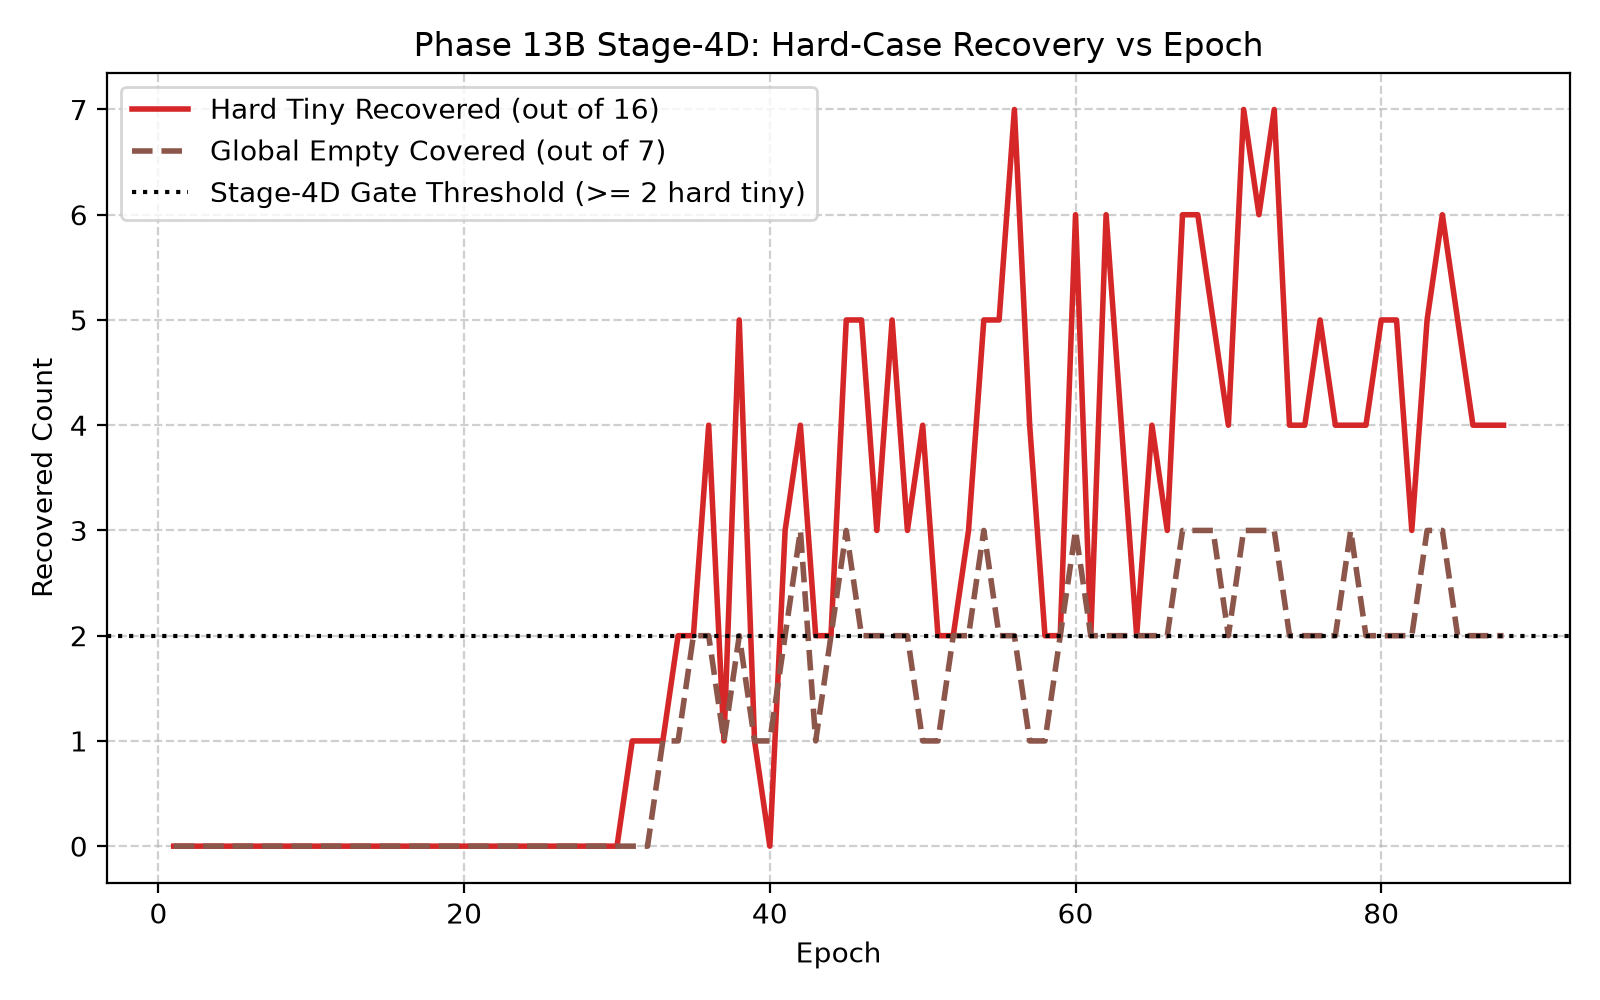

In [8]:
fig_c = PROJECT_ROOT / 'reports/figures/phase13b_stage4d_final_localizer/fig_c_hard_cases_by_epoch.png'
if fig_c.exists():
    display(Image(filename=str(fig_c)))
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, hist['val_hard_tiny_recovered90'], label='Hard Tiny Recovered (/16)', color='#d62728')
    ax.plot(epochs, hist['val_global_empty_images_covered90'], label='Global Empty Covered (/7)', color='#8c564b', linestyle='--')
    ax.set_title('Hard Case Recovery vs Epoch')
    ax.legend()
    plt.show()


## 16. Heatmap Peak Probability Evolution
Mean and median maximum validation heatmap probabilities rising above the $0.10$ prior.

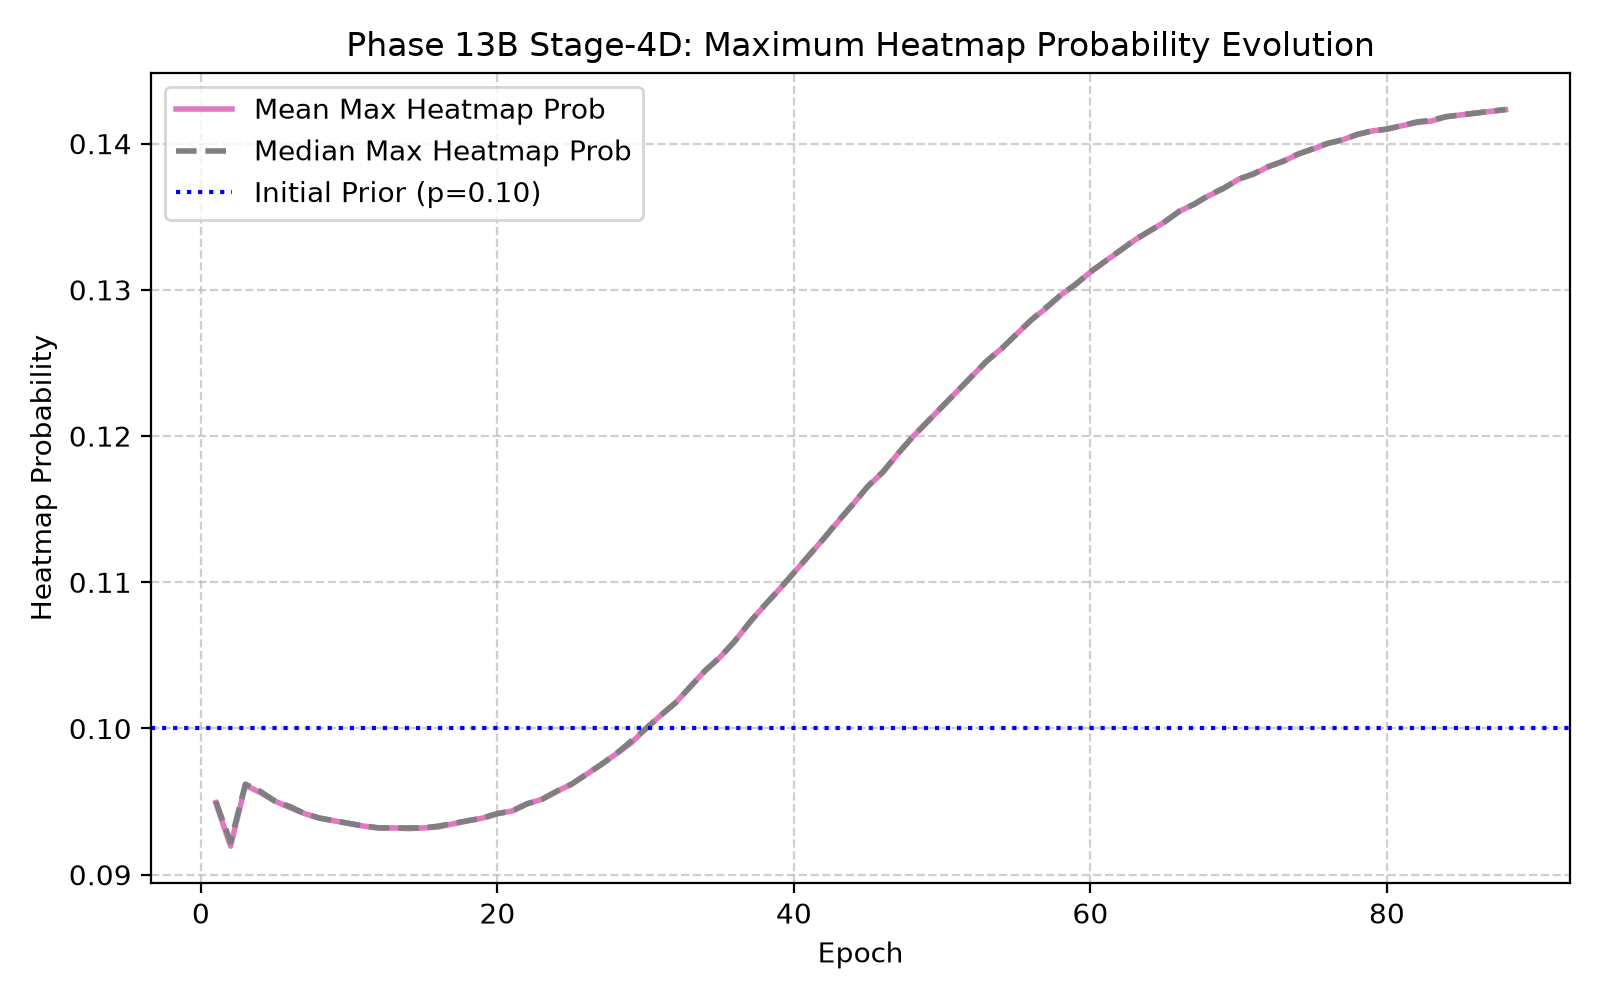

In [9]:
fig_d = PROJECT_ROOT / 'reports/figures/phase13b_stage4d_final_localizer/fig_d_heatmap_probs_by_epoch.png'
if fig_d.exists():
    display(Image(filename=str(fig_d)))
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, hist['mean_max_heatmap'], label='Mean Max Heatmap', color='#e377c2')
    ax.plot(epochs, hist['median_max_heatmap'], label='Median Max Heatmap', color='#7f7f7f', linestyle='--')
    ax.axhline(0.10, color='blue', linestyle=':', label='Initial Prior (0.10)')
    ax.set_title('Heatmap Peak Probability Dynamics')
    ax.legend()
    plt.show()


## 17. Union ROI Area Fraction Evolution
Union ROI area fraction staying well below the feasibility bound of $0.10$ ($10\%$ of image area).

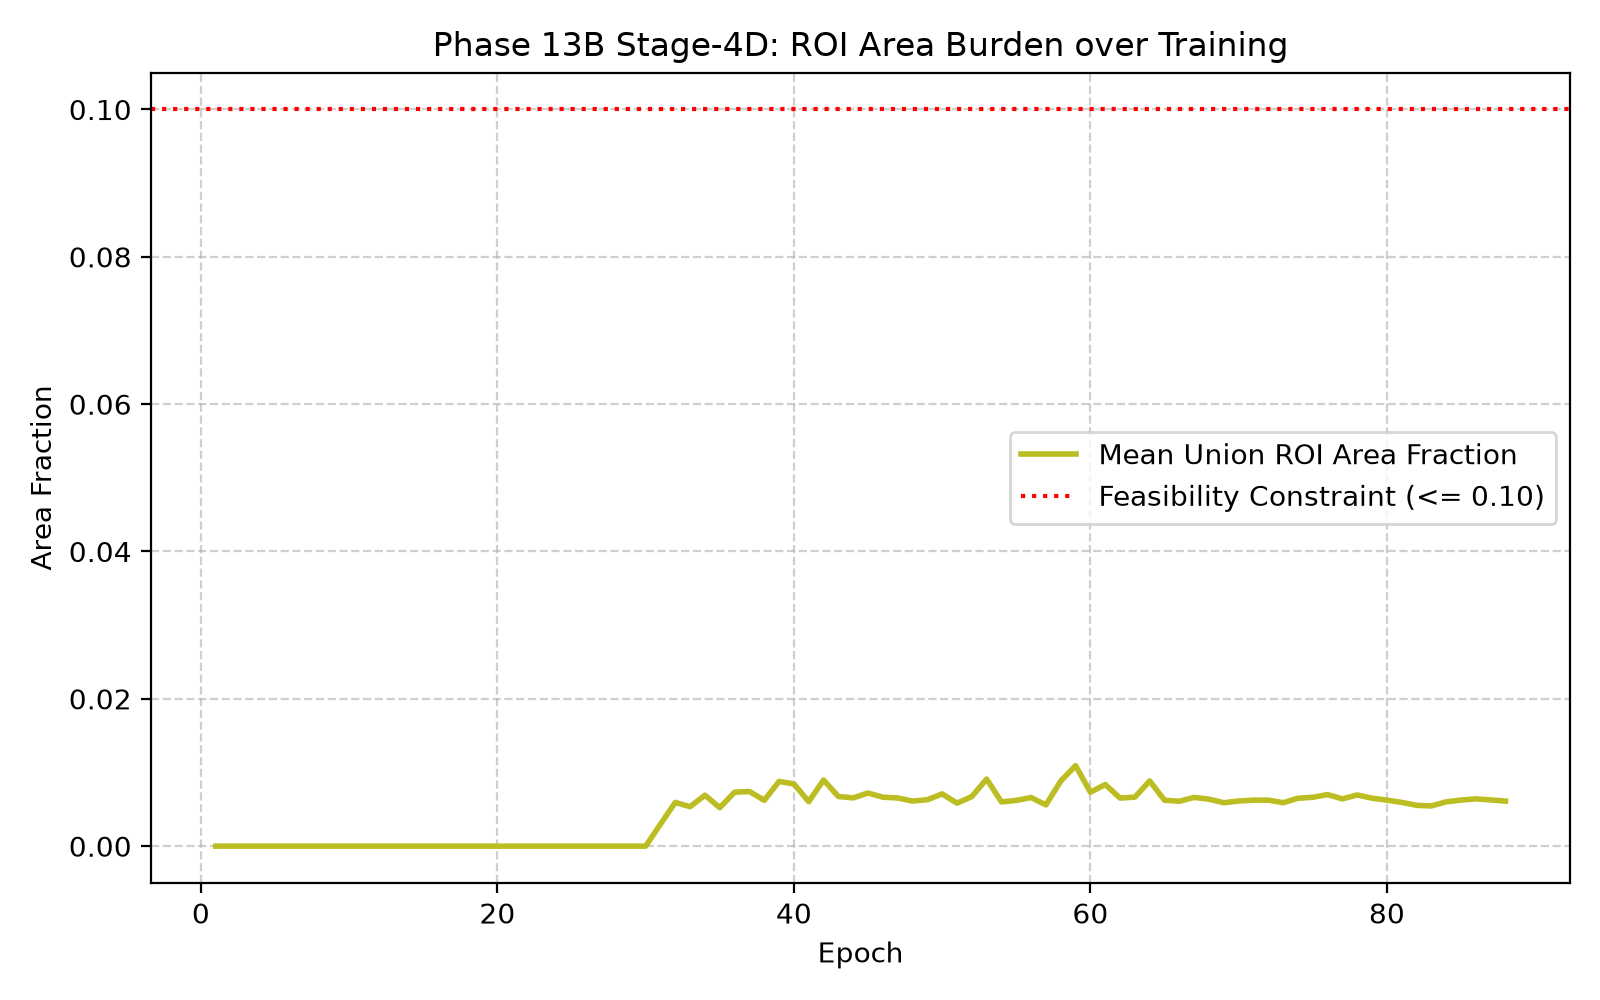

In [10]:
fig_e = PROJECT_ROOT / 'reports/figures/phase13b_stage4d_final_localizer/fig_e_roi_area_by_epoch.png'
if fig_e.exists():
    display(Image(filename=str(fig_e)))


## 18. Proposal Generation Burden Evolution
Mean proposals per image staying below the feasibility limit of $\le 5.0$.

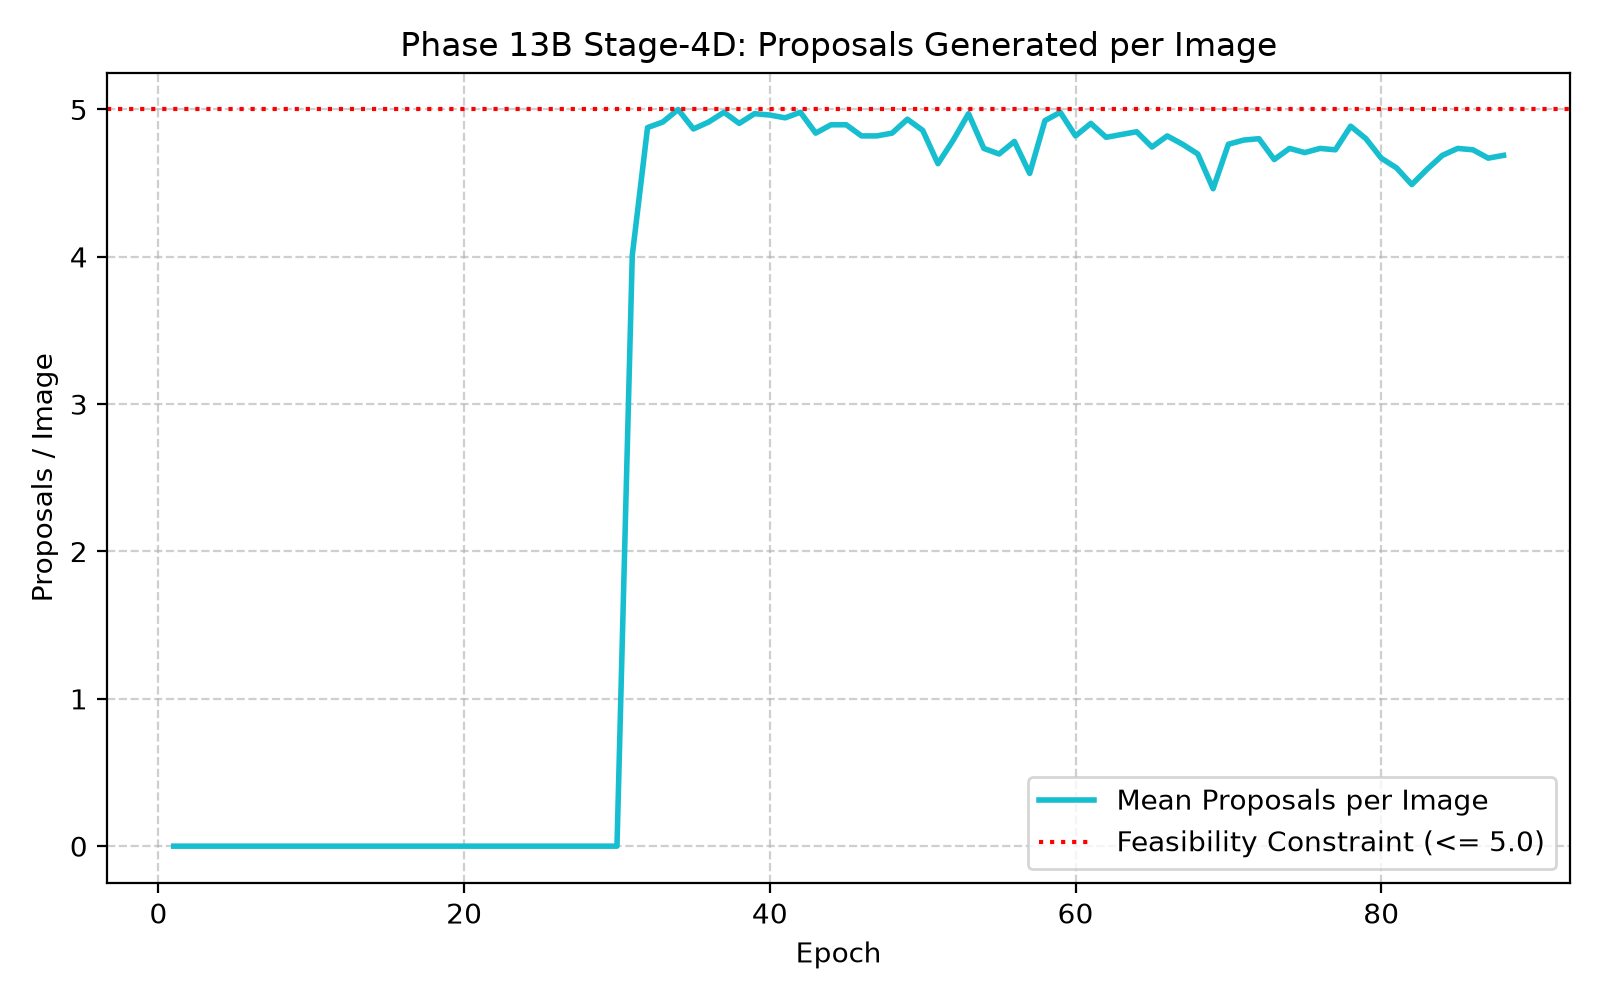

In [11]:
fig_f = PROJECT_ROOT / 'reports/figures/phase13b_stage4d_final_localizer/fig_f_proposals_by_epoch.png'
if fig_f.exists():
    display(Image(filename=str(fig_f)))


## 19. Canonical Selected Configuration & Proposal Search Grid Audit
Best epoch: **73** (early stopping at epoch 88 with patience 15/15).
Selected proposal configuration under the pre-registered lexicographic ranking rule:
- **Threshold:** `0.10`
- **Margin:** `0.20`
- **TopK:** `5`
- **NMS IoU:** `0.30`

The 20-configuration proposal search grid (`phase13b_stage4d_proposal_grid.csv`) was evaluated across thresholds {0.1, 0.2, 0.3, 0.4, 0.5}, margins {0.10, 0.20}, top_k {3, 5}, and NMS IoU 0.30.

In [12]:
# 1. Selected Configuration Table
sel_cfg_path = PROJECT_ROOT / 'reports/tables/phase13b_stage4d_selected_config.csv'
sel_cfg = pd.read_csv(sel_cfg_path)
print("Canonical Selected Configuration:")
display(sel_cfg)

# 2. Proposal Grid Audit
grid_path = PROJECT_ROOT / 'reports/tables/phase13b_stage4d_proposal_grid.csv'
assert grid_path.exists(), f"Proposal grid artifact missing: {grid_path}"
grid_df = pd.read_csv(grid_path)
print("Proposal Search Grid:", len(grid_df), "configurations evaluated")
assert len(grid_df) == 20, f"Expected 20 grid configurations, found {len(grid_df)}"

# Verify canonical configuration presence in grid
match = grid_df[
    (grid_df['threshold'] == 0.10) & 
    (grid_df['margin'] == 0.20) & 
    (grid_df['top_k'] == 5) & 
    (grid_df['nms_iou'] == 0.30)
]
assert len(match) == 1, "Canonical selected configuration not found uniquely in proposal grid!"
print("Canonical config verified in proposal grid: PASS")
display(grid_df[['threshold', 'margin', 'top_k', 'nms_iou', 'tiny_recall90', 'overall_recall90', 'hard_tiny_recovered90', 'mean_roi_area_fraction', 'mean_proposals_per_image', 'feasible']])


Canonical Selected Configuration:


,threshold,margin,top_k,nms_iou,hard_tiny_recovered90,global_empty_images_covered90,global_empty_components_covered90,tiny_recall90,overall_recall90,overall_recall50,any_overlap_recall,mean_coverage,multi_component_recall90,mean_proposals_per_image,mean_roi_area_fraction,feasible,p90_roi_area_fraction,p95_roi_area_fraction,max_roi_area_fraction,median_roi_area_fraction
0,0.1,0.2,5,0.3,7,3,4,0.726027,0.641026,0.788462,0.865385,0.782162,0.61,4.660377,0.005899,True,0.010288,0.012782,0.078506,0.00393


Proposal Search Grid: 20 configurations evaluated
Canonical config verified in proposal grid: PASS


,threshold,margin,top_k,nms_iou,tiny_recall90,overall_recall90,hard_tiny_recovered90,mean_roi_area_fraction,mean_proposals_per_image,feasible
0,0.1,0.1,3,0.3,0.534247,0.467949,3,0.003572,2.952830,True
1,0.1,0.1,5,0.3,0.630137,0.557692,5,0.004353,4.660377,True
2,0.1,0.2,3,0.3,0.616438,0.532051,4,0.004832,2.952830,True
3,0.1,0.2,5,0.3,0.726027,0.641026,7,0.005899,4.660377,True
4,0.2,0.1,3,0.3,0.000000,0.000000,0,0.000000,0.000000,True
5,0.2,0.1,5,0.3,0.000000,0.000000,0,0.000000,0.000000,True
6,0.2,0.2,3,0.3,0.000000,0.000000,0,0.000000,0.000000,True
7,0.2,0.2,5,0.3,0.000000,0.000000,0,0.000000,0.000000,True
8,0.3,0.1,3,0.3,0.000000,0.000000,0,0.000000,0.000000,True
9,0.3,0.1,5,0.3,0.000000,0.000000,0,0.000000,0.000000,True


## 20. Size-Stratified Localization Performance
Breakdown across calculus size strata defined by `kub_size_v1` on the 106 KUB validation images.

,Size,GT,covered90,missed,recall90,covered50,recall50,any_overlap_recall,mean_coverage
0,TINY,73,53,20,0.726027,56,0.767123,0.780822,0.761172
1,SMALL,29,21,8,0.724138,26,0.896552,1.000000,0.885880
2,MEDIUM,36,19,17,0.527778,26,0.722222,0.916667,0.757339
3,LARGE,18,7,11,0.388889,15,0.833333,0.888889,0.749833
4,ALL,156,100,56,0.641026,123,0.788462,0.865385,0.782162


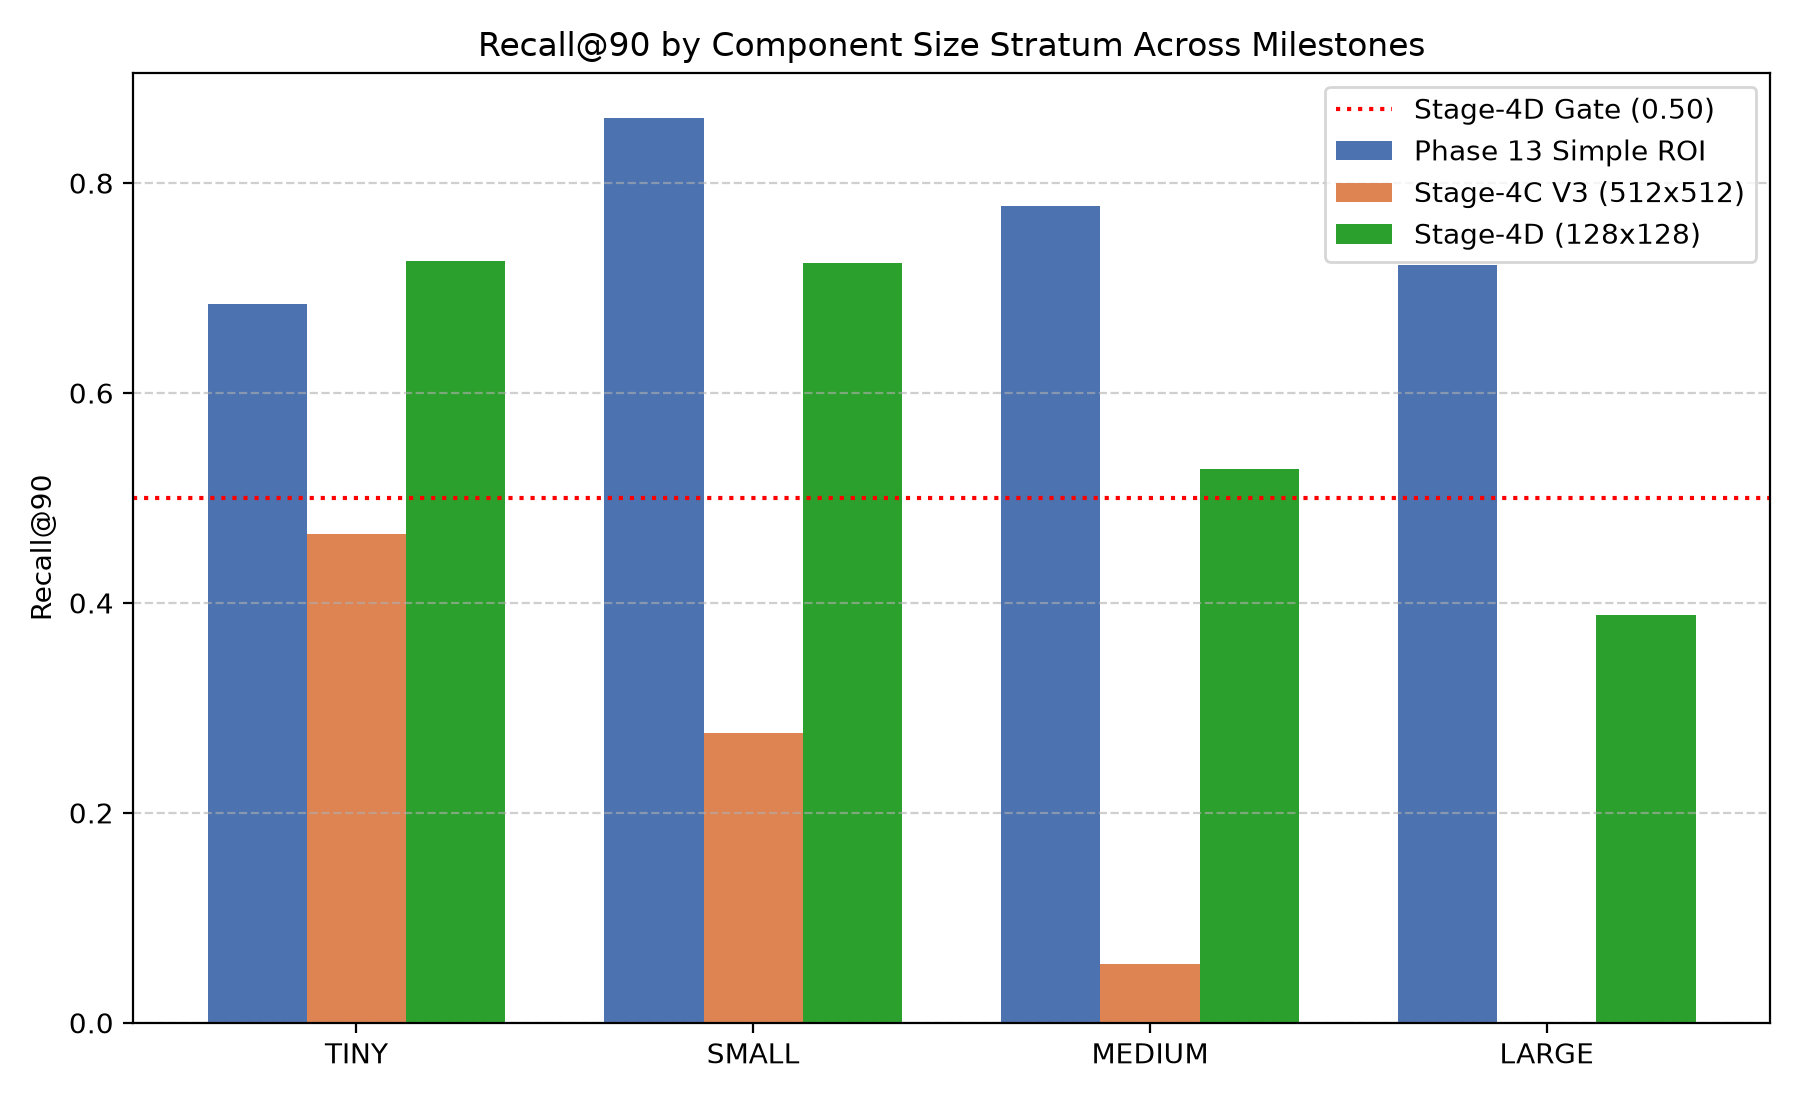

In [13]:
size_path = PROJECT_ROOT / 'reports/tables/phase13b_stage4d_size_summary.csv'
size_df = pd.read_csv(size_path)
display(size_df)

fig_h = PROJECT_ROOT / 'reports/figures/phase13b_stage4d_final_localizer/fig_h_size_stratified_recall.png'
if fig_h.exists():
    display(Image(filename=str(fig_h)))


## 21. Hard Tiny Calculus Localization Analysis
Detailed audit of the 16 Hard Tiny calculi missed by standard full-field global segmentation models.

In [14]:
comp_path = PROJECT_ROOT / 'reports/tables/phase13b_stage4d_best_val_per_component.csv'
comp_df = pd.read_csv(comp_path)
hard_tiny = comp_df[comp_df['hard_tiny'] == True]
display(hard_tiny[['sample_id', 'component_id', 'coverage_fraction', 'covered90', 'covered50', 'any_overlap', 'best_proposal_rank', 'best_proposal_score']])
print(f"Hard Tiny Recovered@90: {hard_tiny['covered90'].sum()} / 16 ({hard_tiny['covered90'].mean():.2%})")


,sample_id,component_id,coverage_fraction,covered90,covered50,any_overlap,best_proposal_rank,best_proposal_score
15,8959dfc29ab5e06d0b2a0f41a4729dde,2,0.000000,False,False,False,NaN,NaN
21,b0473630de9211114c94c7dc0363ebd9,1,0.000000,False,False,False,NaN,NaN
25,a20fe2c1ca04026ab0d036e8dcdd9cca,1,1.000000,True,True,True,3.0,0.138794
35,8c8d2107815002b7913bd6a42f93b394,1,1.000000,True,True,True,5.0,0.138428
36,8c8d2107815002b7913bd6a42f93b394,2,1.000000,True,True,True,5.0,0.138428
39,ad4af1ce1b3dde6ad04fa095aacd92f5,1,0.000000,False,False,False,NaN,NaN
43,9f367e7db192bfe532ace746fd788fb9,2,0.000000,False,False,False,NaN,NaN
67,6a5d5c051d6c898d98c90422da190bf0,2,0.000000,False,False,False,NaN,NaN
69,a626dd389032147c7d4ebd2b1db39e45,1,0.000000,False,False,False,NaN,NaN
71,f860cbfe7c79e5772795a64bac5de7e7,1,1.000000,True,True,True,2.0,0.138794


Hard Tiny Recovered@90: 7 / 16 (43.75%)


## 22. Global-Empty Image Case Analysis
Evaluation of the 7 validation images where global segmentation models produced 0 foreground pixels.

In [15]:
img_path = PROJECT_ROOT / 'reports/tables/phase13b_stage4d_best_val_per_image.csv'
img_df = pd.read_csv(img_path)
empty_imgs = img_df[img_df['global_empty_image'] == True]
display(empty_imgs[['sample_id', 'num_gt_components', 'num_covered90', 'num_proposals', 'roi_area_fraction']])
print(f"Global Empty Images Covered@90: {(empty_imgs['num_covered90'] > 0).sum()} / 7")


,sample_id,num_gt_components,num_covered90,num_proposals,roi_area_fraction
16,b0473630de9211114c94c7dc0363ebd9,1,0,5,0.002652
24,8c8d2107815002b7913bd6a42f93b394,2,2,5,0.006525
26,ad4af1ce1b3dde6ad04fa095aacd92f5,1,0,1,0.000570
27,abe658fa57a12b1665a96d00beeffae0,2,1,3,0.002292
48,f860cbfe7c79e5772795a64bac5de7e7,1,1,5,0.002962
54,e1e165d69d6844c8a599786d865cdd21,2,0,5,0.002652
95,5dd4436a2065b8855ce1dfbed228bce7,2,0,5,0.001737


Global Empty Images Covered@90: 3 / 7


## 23. Milestone Comparison: Stage-4C (512-grid) vs Stage-4D (128-grid)
Direct comparison between the un-downsampled 512-grid CenterNet model and the redesigned 128-grid model.

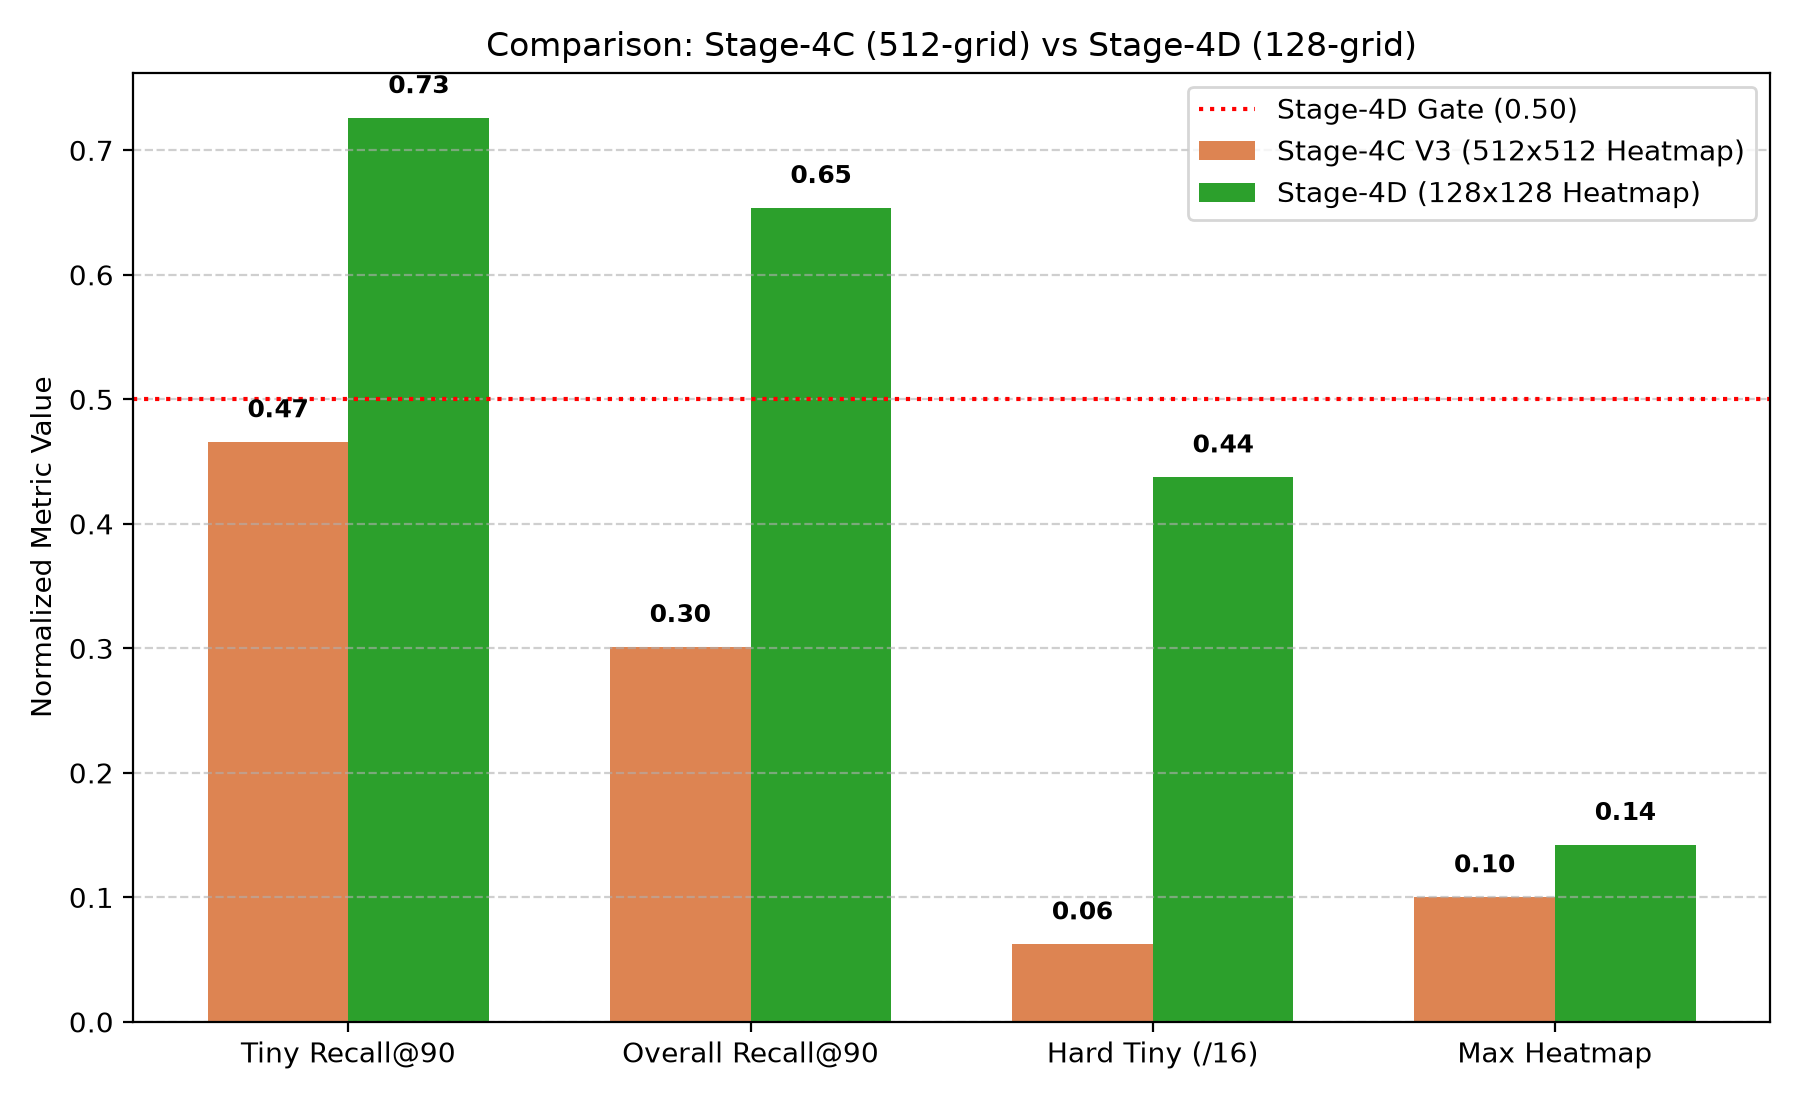

,Metric,Stage-4C V3 (Clean),Stage-4D Redesign
0,Output Heatmap Grid,"512 x 512 (262,144 px)","128 x 128 (16,384 px)"
1,Target Sigma,3.0 pixels,0.75 pixels (geometrically equivalent)
2,Negative Focal Penalty,1.0x (Overwhelming),~16.0x reduction
3,Best Validation Epoch,97,73
4,Tiny Recall@90,46.58% (34 / 73),72.60% (53 / 73)
5,Overall Recall@90,28.21% (44 / 156),64.10% (100 / 156)
6,Hard Tiny Recovered@90,1 / 16 (6.25%),7 / 16 (43.75%)
7,Global-Empty Covered@90,1 / 7 (14.29%),3 / 7 (42.86%)
8,Mean Union ROI Area Fraction,0.000863 (0.09%),0.005899 (0.59%)
9,Mean Proposals per Image,3.18,4.66


In [16]:
fig_g = PROJECT_ROOT / 'reports/figures/phase13b_stage4d_final_localizer/fig_g_stage4c_vs_stage4d_comparison.png'
if fig_g.exists():
    display(Image(filename=str(fig_g)))

comp_data = [
    {"Metric": "Output Heatmap Grid", "Stage-4C V3 (Clean)": "512 x 512 (262,144 px)", "Stage-4D Redesign": "128 x 128 (16,384 px)"},
    {"Metric": "Target Sigma", "Stage-4C V3 (Clean)": "3.0 pixels", "Stage-4D Redesign": "0.75 pixels (geometrically equivalent)"},
    {"Metric": "Negative Focal Penalty", "Stage-4C V3 (Clean)": "1.0x (Overwhelming)", "Stage-4D Redesign": "~16.0x reduction"},
    {"Metric": "Best Validation Epoch", "Stage-4C V3 (Clean)": "97", "Stage-4D Redesign": "73"},
    {"Metric": "Tiny Recall@90", "Stage-4C V3 (Clean)": "46.58% (34 / 73)", "Stage-4D Redesign": "72.60% (53 / 73)"},
    {"Metric": "Overall Recall@90", "Stage-4C V3 (Clean)": "28.21% (44 / 156)", "Stage-4D Redesign": "64.10% (100 / 156)"},
    {"Metric": "Hard Tiny Recovered@90", "Stage-4C V3 (Clean)": "1 / 16 (6.25%)", "Stage-4D Redesign": "7 / 16 (43.75%)"},
    {"Metric": "Global-Empty Covered@90", "Stage-4C V3 (Clean)": "1 / 7 (14.29%)", "Stage-4D Redesign": "3 / 7 (42.86%)"},
    {"Metric": "Mean Union ROI Area Fraction", "Stage-4C V3 (Clean)": "0.000863 (0.09%)", "Stage-4D Redesign": "0.005899 (0.59%)"},
    {"Metric": "Mean Proposals per Image", "Stage-4C V3 (Clean)": "3.18", "Stage-4D Redesign": "4.66"},
    {"Metric": "Mean Max Heatmap Probability", "Stage-4C V3 (Clean)": "~0.1003", "Stage-4D Redesign": "0.1388"},
]
comp_df = pd.DataFrame(comp_data)
display(comp_df)


## 24. Stage-4D Continuation Gate Evaluation
Evaluation against the 5 pre-registered Stage-4D gate criteria:
- **Gate A (Tiny Recall@90 $\ge 0.50$):** $0.726027$ (**PASS**)
- **Gate B (Overall Recall@90 $\ge 0.50$):** $0.641026$ (**PASS**)
- **Gate C (Hard Tiny $\ge 2/16$):** $7 / 16$ (**PASS**)
- **Gate D (Mean ROI Area $\le 0.10$):** $0.005899$ (**PASS**)
- **Gate E (Mean Proposals $\le 5.0$):** $4.660377$ (**PASS**)

In [17]:
gate_path = PROJECT_ROOT / 'reports/tables/phase13b_stage4d_gate_evaluation.csv'
gate_df = pd.read_csv(gate_path)
display(gate_df)
assert gate_df['passed'].all(), "Stage-4D Continuation Gate did not pass all criteria!"
print("Stage-4D Continuation Gate: ALL 5 CRITERIA PASSED")


,criterion,target,achieved,passed
0,A: Tiny recall90 >= 0.50,>= 0.50,0.726027,True
1,B: Overall recall90 >= 0.50,>= 0.50,0.641026,True
2,C: Hard Tiny recovered90 >= 2/16,>= 2,7 / 16,True
3,D: Mean ROI area <= 0.10,<= 0.10,0.005899,True
4,E: Mean proposals/image <= 5.0,<= 5.0,4.6604,True


Stage-4D Continuation Gate: ALL 5 CRITERIA PASSED


## 25. Scientific Interpretation
The Stage-4D result is consistent with the pre-registered hypothesis that reducing the dense heatmap/loss grid can improve compact center localization under this configuration. 

By relieving the overwhelming background focal loss penalty via fixed stride-4 logit pooling, the network escaped the $p \approx 0.10$ prior and learned calibrated peaks for urinary calculi. However, this does not constitute proof of background dominance as the sole failure mechanism, nor does it claim universal superiority or clinical readiness.

## 26. Scientific Limitations
1. **Validation-Only Scope:** All metrics reflect performance strictly on the 106 KUB validation images. The TEST split remains locked.
2. **Single Seed:** Results reflect seed 42. Variance across initializations is unmeasured.
3. **Downstream Uncoupled:** Proposals have not yet been processed by a second-stage refiner model.

## 27. Provenance, Checkpoint Hashes & Discrepancy Reconciliation

### Metric Discrepancy Reconciliation:
Online/recovery monitoring and final canonical evaluation differed for some metrics (e.g. 6/16 vs 7/16 Hard Tiny) because the online path used a fast, approximate tracking accumulator, whereas the canonical offline evaluation (`evaluate_phase13b_stage4d.py`) used fully formed proposal and component matching evaluation. Canonical publication values are from the frozen final evaluation.

### Cryptographic Checkpoint Verification:

In [18]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while chunk := f.read(8192):
            h.update(chunk)
    return h.hexdigest()

best_pt = PROJECT_ROOT / f'checkpoints/{exp_id}/best.pt'
latest_pt = PROJECT_ROOT / f'checkpoints/{exp_id}/latest.pt'

best_sha = sha256_file(best_pt)
latest_sha = sha256_file(latest_pt)
expected_best_sha = "ece906df6c73f2e93c3f873661490bf3cb1a6b82be2d2d93b58c25bc967cbace"

print(f"best.pt SHA-256:   {best_sha}")
print(f"Expected SHA-256:  {expected_best_sha}")
assert best_sha == expected_best_sha, f"SHA mismatch on best.pt! Expected {expected_best_sha}, got {best_sha}"
print("Checkpoint Integrity: PASS")


best.pt SHA-256:   ece906df6c73f2e93c3f873661490bf3cb1a6b82be2d2d93b58c25bc967cbace
Expected SHA-256:  ece906df6c73f2e93c3f873661490bf3cb1a6b82be2d2d93b58c25bc967cbace
Checkpoint Integrity: PASS


## 28. Final Phase-13B Status & Roadmap Boundary

```
PHASE 13B:
COMPLETE

PHASE 13:
COMPLETE / FROZEN

FINAL LOCALIZER:
PROMISING_VALIDATED_ON_VAL

PHASE 14 ENTRY GATE:
NOT_PASSED

PHASE 14:
CLOSED WITHOUT EXECUTION

TEST CONTENT READS:
0

TEST METRICS:
NONE

EXTERNAL:
NO

NEXT SCIENTIFIC PHASE:
NOT STARTED
```